![Python Banner](../../Image/05_01_tree_based_models.png)


# 1.5 Multi-arm/multi-outcome Causal Forest



## Overview

A **Multi-Arm/Multi-Outcome Causal Forest** extends the standard Causal Forest to handle two common real-world complications simultaneously: there may be more than two treatment options (multiple arms), and the researcher may care about more than one outcome at the same time (multiple outcomes). It remains fully within the Generalized Random Forest (GRF) framework, preserving the core properties of honest estimation and non-parametric flexibility.

The key promise of this extension is **information sharing**: by modeling treatment arms and outcomes jointly, the forest can borrow strength across related estimates rather than fitting each comparison in isolation — improving precision, especially when sample sizes per arm are limited.

### When to Use It

A multi-arm/multi-outcome causal forest is the right tool when the research question is of the form: *"How does each treatment affect each outcome, and does this vary across subgroups?"*

Concrete settings include:

-   **Clinical trials** comparing several drugs or dosing regimens on multiple patient health metrics simultaneously (e.g., blood pressure, cholesterol, adverse events).
-   **Policy evaluation** where several interventions (e.g., cash transfers, job training, mentoring) are tested and success is measured across multiple dimensions (e.g., employment rate, income, school attendance).
-   **Marketing experiments** with multiple campaign strategies evaluated on several customer metrics (e.g., click-through rate, conversion, retention).

In all these cases, fitting separate single-arm, single-outcome models would ignore correlations between outcomes and inflate estimation variance — particularly when some arms have few observations.

### Key Concepts

**Multi-arm treatment effects.** With $J$ treatment arms (including control $W = 0$), the forest estimates $J$ separate conditional effects for each individual:

$$\tau_j(X) = E[Y \mid W = j,\, X = x] - E[Y \mid W = 0,\, X = x], \quad j = 1, \ldots, J$$

**Multi-outcome treatment effects.** With $K$ outcomes $Y_1, \ldots, Y_K$, the forest estimates an effect for each combination of arm $j$ and outcome $k$:

$$\tau_{j,k}(X) = E[Y_k \mid W = j,\, X = x] - E[Y_k \mid W = 0,\, X = x]$$

The full output for an individual is therefore a $J \times K$ matrix of treatment effect estimates.

**Joint splitting criterion.** Unlike fitting $J \times K$ independent forests, a single tree's splits are chosen to maximize heterogeneity across *all* arms and outcomes simultaneously, using a joint loss function that respects the covariance structure among outcomes. This is what enables information sharing.

**Nuisance estimation.** Propensity scores $\hat{e}_j(X) = P(W = j \mid X)$ and outcome regressions $\hat{\mu}_k(X)$ are estimated using separate regression forests. Residualizing with these nuisances — forming $\tilde{Y}_k = Y_k - \hat{\mu}_k(X)$ and $\tilde{W}_j = \mathbf{1}(W=j) - \hat{e}_j(X)$ — removes confounding before the causal forest estimates effects.

**Honest estimation.** As in all GRF methods, each tree uses a separate subsample to find splits ($S_1$) and to estimate effects within leaves ($S_2$), preventing overfitting and ensuring asymptotically valid confidence intervals.

### How It Works

![Multi-arm multi-outcome causal forest](../../Image/Multi-arm-multi-outcome-Causal-Forest.png)

A few things worth emphasizing from the pipeline:

**The** $J \times K$ matrix in step 5 is the defining output. Each row is a treatment arm; each column is an outcome. For an individual with covariates $X = x$, every cell gives a separate CATE estimate with its own confidence interval. This is what distinguishes the multi-arm/multi-outcome forest from running $J \times K$ separate causal forests — the joint splitting criterion in step 3 means the covariate partitions reflect *shared* structure across all cells, not independent ones.

**Step 2 (nuisance estimation) is more complex here** than in the binary treatment case. With $J$ arms, the forest must estimate $J$ propensity scores $\hat{e}_j(X)$ — one per arm — and $K$ outcome regressions $\hat{\mu}_k(X)$. These are estimated via separate regression forests and used to form the residuals $\tilde{W}_j$ and $\tilde{Y}_k$ that the causal forest then splits on.

**Information sharing is the key efficiency gain.** When outcomes $Y_1$ and $Y_2$ are correlated (e.g., systolic and diastolic blood pressure), the joint covariance structure in the splitting criterion means that a split informative for one outcome also informs the other. This can substantially reduce variance compared to independent forests, particularly in small-sample regimes.

### Key Differences from Standard Causal Forest

-   `Standard Causal Forest`: Handles one treatment (binary or continuous) and one outcome, estimating a single treatment effect per individual.
-   `Multi-Arm/Multi-Outcome Causal Forest`:
    -   Models multiple treatments (e.g., multiple drugs) and/or multiple outcomes (e.g., multiple health metrics).
    -   Shares information across arms/outcomes to improve estimation efficiency.
    -   Uses a joint objective function to optimize splits for all treatments and outcomes simultaneously.

### Advantages

-   Handles complex experiments with multiple treatments and outcomes.
-   Captures heterogeneity in treatment effects across subgroups.
-   Robust to non-linear relationships and high-dimensional covariates.
-   Improves efficiency by sharing information across arms/outcomes.

### Limitations

-   Requires sufficient sample size for each treatment arm and outcome.
-   Assumes unconfoundedness (no unmeasured confounders) unless combined with other methods (e.g., instrumental variables).
-   Computationally intensive for large datasets or many outcomes.
-   Interpretability can be challenging due to complex output (multiple effects per individual).



## Multi-arm/multi-outcome Causal Forest in Python

This tutorial implements a **multi-arm/multi-outcome causal forest** with `MultiArmCausalForest` from PyCausalML. The example simulates a three-arm treatment and two outcomes from `Data/patients.csv`.


## Setup

This notebook fits **`MultiArmCausalForest`** from **[PyCausalML](https://github.com/zia207/PyCausalML)** (`pycausalml.tree_based_models`).

`fit(X, treatment, y)` returns the fitted estimator. `predict` returns a NumPy array of conditional average treatment effects. A fitted model also exposes `explain` and `plot_shap`.

Install the package from this repository, with the plotting and boosting extras.

The three-arm patient example is built with `make_patient_multiarm` from `causal_tree_methods.py` in this folder. Arm labels are coded `placebo=0`, `A=1`, `B=2`, and the baseline arm is `0`.


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]", "statsmodels",
])
print("PyCausalML ready.")


PyCausalML ready.


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from pycausalml import (
    MultiArmCausalForest,
    explain_cate,
)

import sys
from pathlib import Path

def _add_methods_path():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        for rel in (
            Path("causal_tree_methods.py"),
            Path("Tutorials") / "05_01_Tree_Based_Models" / "causal_tree_methods.py",
            Path("Notebook") / "05_01_Tree_Based_Models" / "causal_tree_methods.py",
        ):
            path = cand / rel
            if path.is_file():
                sys.path.insert(0, str(path.parent))
                return
    raise FileNotFoundError("causal_tree_methods.py was not found")

_add_methods_path()
from causal_tree_methods import (
    make_patient_multiarm,
)

def find_repo_root(start=None) -> Path:
    here = Path(start or Path.cwd()).resolve()
    for cand in [here, *here.parents]:
        if (cand / "Data").is_dir() and (cand / "Image").is_dir():
            return cand
    raise FileNotFoundError("Could not find a folder containing Data/ and Image/.")

def data_path(filename: str) -> Path:
    return find_repo_root() / "Data" / filename

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
print("Imported PyCausalML")


Imported PyCausalML


### Prepare the patient dataset

The example is built from `Data/patients.csv`: real age, comorbidity, baseline risk, and sex, a simulated three-arm treatment (`placebo`, `A`, `B`), observed log length of stay, and a simulated binary clinical response that improves under A and more so under B.

`make_patient_multiarm` builds that design from `Data/patients.csv`:

-   Draws a three-level `treatment` (`placebo`, `A`, `B`) with probabilities 40%, 30%, and 30%.
-   Keeps observed log length of stay (`log_los`) as the first outcome. Treatment is randomized, so its effect on length of stay is null.
-   Simulates a binary clinical `response` that is higher under arm A and higher still under arm B.


In [3]:
design = make_patient_multiarm(n=2000, random_state=123)
frame = design["frame"]
X, Y_mat, W = design["X"], design["Y"], design["W"]
feature_names = design["feature_names"]
outcome_names = design["outcome_names"]
rng = np.random.default_rng(123)
n = len(W)
train_idx = rng.choice(n, size=int(0.8 * n), replace=False)
test_idx = np.setdiff1d(np.arange(n), train_idx)
X_train, X_test = X[train_idx], X[test_idx]
W_train, W_test = W[train_idx], W[test_idx]
Y_train, Y_test = Y_mat[train_idx], Y_mat[test_idx]
print(pd.Series(W_train).value_counts())
print("outcomes", outcome_names)


placebo    641
A          498
B          461
Name: count, dtype: int64
outcomes ['log_los', 'response']


### Train the Multi-arm/Multi-outcome Causal Forest

The arms are placebo, A, and B, and the outcomes are log length of stay and clinical response. `MultiArmCausalForest` estimates contrasts against a baseline for one outcome at a time, so we fit a separate model for each outcome.


In [4]:
ARM = {"placebo": 0, "A": 1, "B": 2}
CONTRAST = {1: "A - placebo", 2: "B - placebo"}

def encode_arm(labels):
    return np.array([ARM[str(a)] for a in np.asarray(labels)])

def contrast_frame(model, rows):
    pred = np.asarray(model.predict(rows))
    columns = [CONTRAST[int(arm)] for arm in model.arms_]
    return pd.DataFrame(pred, columns=columns)

def ate_table(model):
    rows = []
    for arm, forest in zip(model.arms_, model.forests_):
        ate = forest.average_treatment_effect()
        rows.append({
            "contrast": CONTRAST[int(arm)],
            "estimate": ate["estimate"],
            "std.err": ate["std.err"],
        })
    return pd.DataFrame(rows)

W_train_code = encode_arm(W_train)
macf_log_los = MultiArmCausalForest(baseline=0, num_trees=60, min_node_size=8, random_state=1)
macf_response = MultiArmCausalForest(baseline=0, num_trees=60, min_node_size=8, random_state=2)
macf_log_los.fit(X_train, W_train_code, Y_train[:, 0], feature_names=feature_names)
macf_response.fit(X_train, W_train_code, Y_train[:, 1], feature_names=feature_names)
print("Fitted one forest per outcome")


Fitted one forest per outcome


### Predict on the test data set

In [5]:
tau_hat_log_los = contrast_frame(macf_log_los, X_test)
tau_hat_response = contrast_frame(macf_response, X_test)
print("log length of stay")
print(tau_hat_log_los.head())
print("clinical response")
print(tau_hat_response.head())


log length of stay
   A - placebo  B - placebo
0     0.034385     0.283482
1     0.015815    -0.142222
2    -0.029373    -0.144031
3    -0.156336     0.151620
4    -0.116162     0.273966
clinical response
   A - placebo  B - placebo
0     0.076200     0.504776
1     0.225444     0.192521
2     0.398804     0.322517
3     0.208306     0.167362
4     0.027868     0.089350


### Calculate Doubly Robust Average Treatment Effects (AIPW)

We compute the average treatment effects (ATE) for each arm relative to placebo with the doubly robust scores stored on each fitted forest.


In [6]:
print("Average treatment effects for log_los")
print(ate_table(macf_log_los).round(3))
print("Average treatment effects for response")
print(ate_table(macf_response).round(3))


Average treatment effects for log_los
      contrast  estimate  std.err
0  A - placebo     0.050    0.032
1  B - placebo     0.102    0.032
Average treatment effects for response
      contrast  estimate  std.err
0  A - placebo     0.106     0.03
1  B - placebo     0.213     0.03


### Plot Variable Importance

Finally, we plot covariate importance for each outcome.

#### Log length of stay


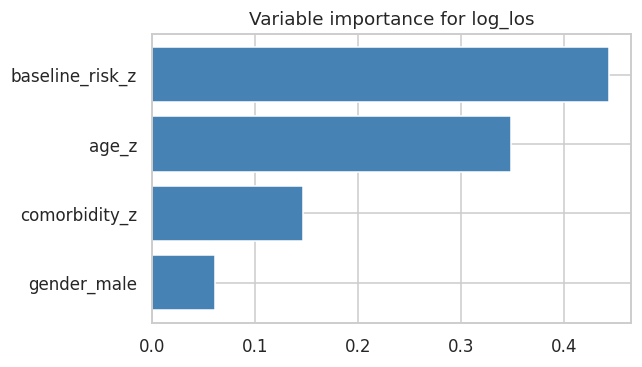

In [7]:
def plot_importance(model, title):
    imp = pd.DataFrame({
        "Variable": feature_names,
        "Importance": model.feature_importance(),
    }).sort_values("Importance")
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.barh(imp["Variable"], imp["Importance"], color="steelblue")
    ax.set_title(title)
    fig.tight_layout()
    plt.show()

plot_importance(macf_log_los, "Variable importance for log_los")


#### Clinical response

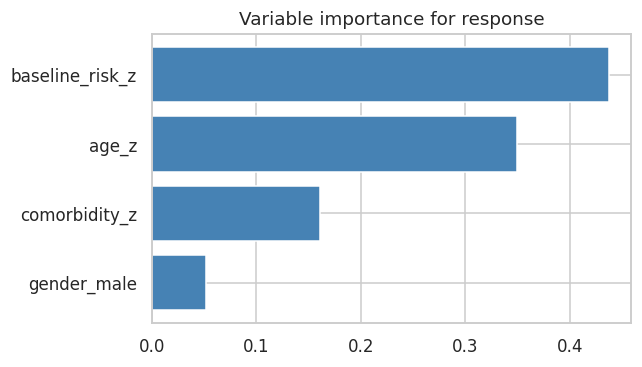

In [8]:
plot_importance(macf_response, "Variable importance for response")


### SHAP values for each outcome

`explain_cate()` computes SHAP values for the CATE predictions of each outcome. Here we show both log length of stay and clinical response.

`contrast_frame` labels the columns of `predict` as **"A - placebo"** and **"B - placebo"**.


In [9]:
print(contrast_frame(macf_response, X_test).columns.tolist())


['A - placebo', 'B - placebo']


Those column names are **"A - placebo"** and **"B - placebo"**.

#### Predicted contrasts


In [10]:
print(contrast_frame(macf_log_los, X_test[:5]))
print(contrast_frame(macf_response, X_test[:5]))


   A - placebo  B - placebo
0     0.034385     0.283482
1     0.015815    -0.142222
2    -0.029373    -0.144031
3    -0.156336     0.151620
4    -0.116162     0.273966
   A - placebo  B - placebo
0     0.076200     0.504776
1     0.225444     0.192521
2     0.398804     0.322517
3     0.208306     0.167362
4     0.027868     0.089350


#### Prediction wrappers (one per contrast)

Each wrapper returns one contrast column so `explain_cate()` can explain one arm at a time.


In [11]:
class _Contrast:
    def __init__(self, model, column):
        self.model = model
        self.column = column
        self.feature_names_ = feature_names

    def predict(self, new_x):
        return np.asarray(self.model.predict(new_x))[:, self.column]

print("Contrast wrappers ready:", list(CONTRAST.values()))


Contrast wrappers ready: ['A - placebo', 'B - placebo']


#### Compute SHAP values for each contrast


In [12]:
sv_A = explain_cate(_Contrast(macf_response, 0), X_test, feature_names=feature_names, max_samples=30, random_state=1)
sv_B = explain_cate(_Contrast(macf_response, 1), X_test, feature_names=feature_names, max_samples=30, random_state=1)
print(np.round(sv_A.values[:3], 3))


[[-0.142 -0.194 -0.152  0.   ]
 [ 0.067 -0.302  0.071  0.016]
 [ 0.047  0.     0.093  0.001]]


### Exact Kernel SHAP values (preview)

In [13]:
print(pd.DataFrame(sv_A.values, columns=feature_names).head().round(3))


   age_z  comorbidity_z  baseline_risk_z  gender_male
0 -0.142         -0.194           -0.152        0.000
1  0.067         -0.302            0.071        0.016
2  0.047          0.000            0.093        0.001
3  0.011         -0.294           -0.214       -0.000
4 -0.046         -0.238           -0.081       -0.019


### SHAP summaries


In [14]:
print("A vs placebo — response")
print(pd.DataFrame({"feature": feature_names, "mean_abs_shap": np.abs(sv_A.values).mean(0)}))


A vs placebo — response
           feature  mean_abs_shap
0            age_z       0.078815
1    comorbidity_z       0.238589
2  baseline_risk_z       0.089441
3      gender_male       0.019149


### Importance Plots

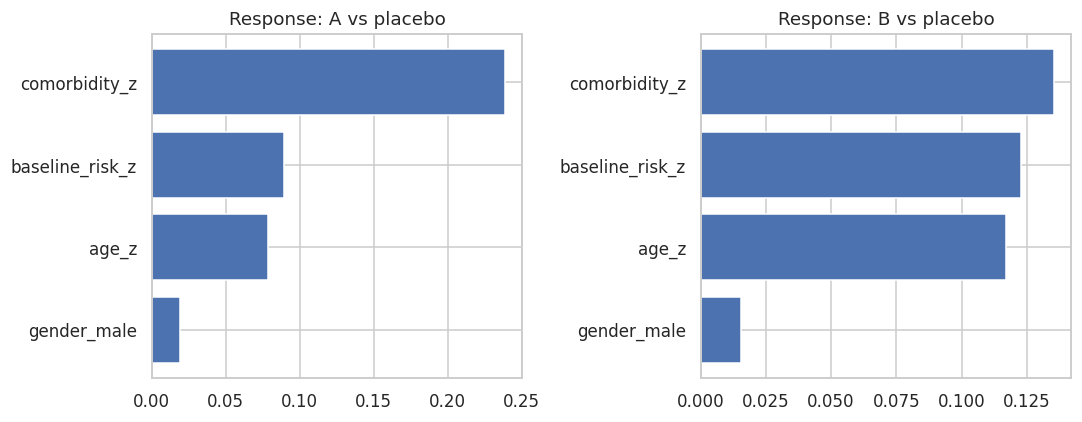

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, sv, title in (
    (axes[0], sv_A, "Response: A vs placebo"),
    (axes[1], sv_B, "Response: B vs placebo"),
):
    order = np.argsort(np.abs(sv.values).mean(0))
    ax.barh(np.array(feature_names)[order], np.abs(sv.values).mean(0)[order], color="#4C72B0")
    ax.set_title(title)
fig.tight_layout()
plt.show()


### Dependence plots for each covariate

In [16]:
print("Features:", feature_names)


Features: ['age_z', 'comorbidity_z', 'baseline_risk_z', 'gender_male']


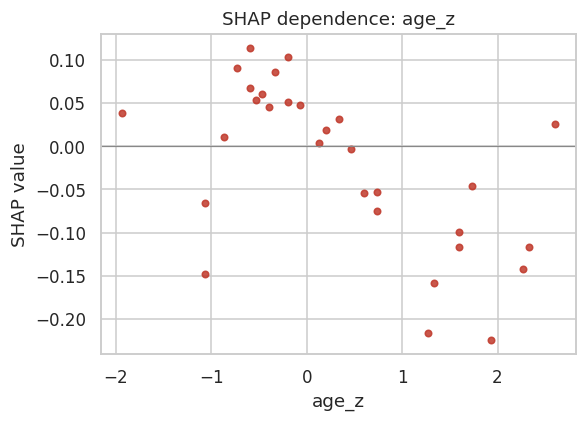

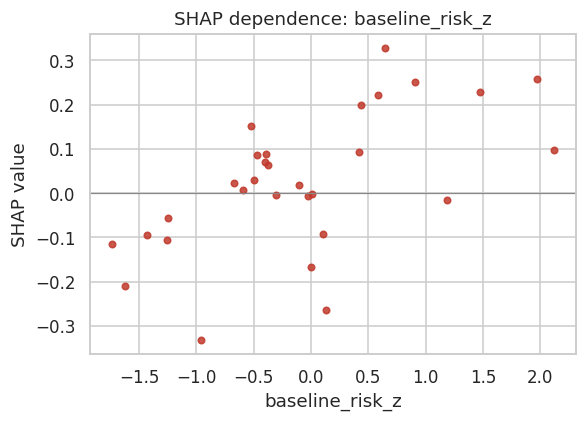

In [17]:
sv_A.plot_dependence("age_z")
plt.show()
sv_B.plot_dependence("baseline_risk_z")
plt.show()


## Summary and Conclusion

Multi-arm/multi-outcome causal forests are powerful tools for estimating heterogeneous treatment effects in complex settings with multiple treatments and outcomes. By leveraging the flexibility of random forests, they provide robust estimates that account for individual differences and correlations between outcomes. This approach is particularly useful in fields like healthcare, policy evaluation, and marketing, where understanding the nuanced effects of different interventions is crucial. This tutorial used `MultiArmCausalForest` from PyCausalML to analyze treatment effects on two outcomes at once. This approach allows researchers to gain deeper insights into the effectiveness of various interventions across diverse populations and outcomes, ultimately leading to more informed decision-making.

SHAP values from `explain_cate()` interpret the heterogeneous treatment effects, so the same workflow covers estimation and interpretation.

For a boosted multi-arm approach that fits one outcome model per arm and then forms contrasts relative to a baseline, see the multi-arm causal boost tutorial in this folder.

## Resources

1.  Wager, S., & Athey, S. (2018). Estimation and Inference of Heterogeneous Treatment Effects using Random Forests. JASA.

2.  Athey, S., Tibshirani, J., & Wager, S. (2019). Generalized Random Forests. Ann. Statist.

3.  The estimator in this tutorial is `MultiArmCausalForest` in PyCausalML.
